In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [17]:
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1]) # AND gate outputs

In [3]:
weights = np.random.rand(2) * 0.1

In [4]:
weights

array([0.06997683, 0.09951782])

In [5]:
bias = np.random.rand(1)[0] * 0.1

In [6]:
bias

0.025566738786934187

In [18]:
learning_rate = 0.1

In [25]:
for _ in range(20):
    for x,y in zip(X_and,y_and):
        z = np.dot(x, weights) + bias
        prediction = step_function(z)
        error = y - prediction
        weights = weights + learning_rate * error * x
        bias = bias + learning_rate * error

In [22]:
def step_function(z):
    if z>=0:
        return 1
    else:
        return 0

In [26]:
for x in X_and:
    z = np.dot(x, weights) + bias
    prediction = step_function(z)
    print(f"Input: {x} --> Prediction: {prediction}")


Input: [0 0] --> Prediction: 0
Input: [0 1] --> Prediction: 0
Input: [1 0] --> Prediction: 0
Input: [1 1] --> Prediction: 1


In [27]:
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [28]:
X_shapes = np.array([
    [4, 1.0], [4, 1.05], [4, 0.95],  # Squares
    [0, 1.0], [0, 1.1], [0, 0.9],    # Circles
    [4, 0.5], [0, 2.0]               # Noisy points
])

y_shapes = np.array([0, 0, 0, 1, 1, 1, 0, 1])

In [30]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_shapes,
    y_shapes,
    test_size=0.3,
    random_state=42
)


In [31]:
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    max_iter=500,
    random_state=42,
    solver='adam'
)


In [32]:
mlp.fit(X_train_s, y_train_s)


C:\Users\shadm\AppData\Roaming\Python\Python312\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(5,), max_iter=500, random_state=42)

In [33]:
y_pred = mlp.predict(X_test_s)


In [35]:
accuracy = accuracy_score(y_test_s, y_pred)
accuracy

1.0

In [36]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

In [37]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


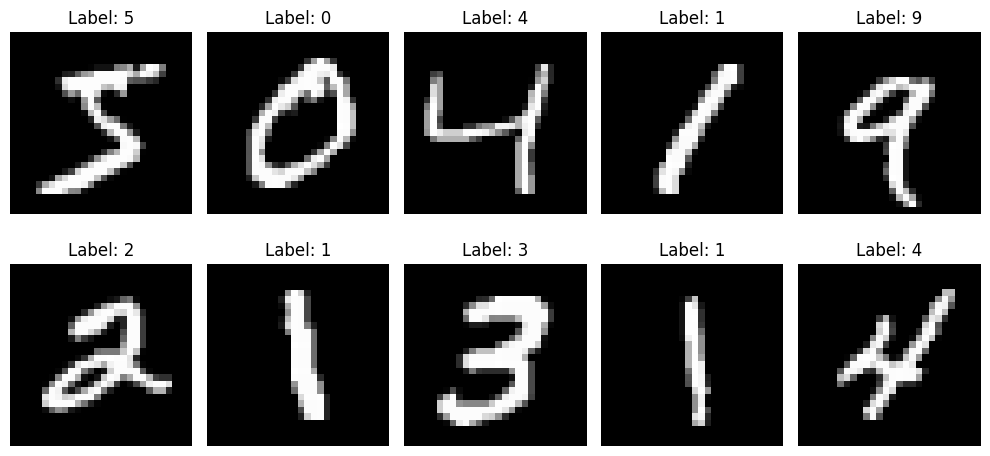

In [38]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [39]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [40]:
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

In [41]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'), # hidden layer consist of 128 neurons

    Dense(10, activation='softmax') # produces 10 output probabilities
])

C:\Users\shadm\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [42]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [43]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9220 - loss: 0.2735 - val_accuracy: 0.9705 - val_loss: 0.1190
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9639 - loss: 0.1200 - val_accuracy: 0.9722 - val_loss: 0.0987
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9761 - loss: 0.0800 - val_accuracy: 0.9767 - val_loss: 0.0827
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9821 - loss: 0.0603 - val_accuracy: 0.9783 - val_loss: 0.0817
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9854 - loss: 0.0466 - val_accuracy: 0.9790 - val_loss: 0.0790
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9887 - loss: 0.0368 - val_accuracy: 0.9803 - val_loss: 0.0761
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9910 - loss: 0.0292 - val_accuracy: 0.9780 - val_loss: 0.0856
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9922 - loss: 0.0240 - 

In [44]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9760 - loss: 0.0902
Test Loss: 0.09023081511259079
Test Accuracy: 0.9760000109672546
Test Accuracy (%): 97.60000109672546


In [45]:
predictions = model.predict(X_test[:10])

for i in range(10):

    predicted_label = np.argmax(predictions[i])
    actual_label = np.argmax(y_test[i])

    print(
        f"Actual: {actual_label}, "
        f"Predicted: {predicted_label}"
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Actual: 7, Predicted: 7
Actual: 2, Predicted: 2
Actual: 1, Predicted: 1
Actual: 0, Predicted: 0
Actual: 4, Predicted: 4
Actual: 1, Predicted: 1
Actual: 4, Predicted: 4
Actual: 9, Predicted: 9
Actual: 5, Predicted: 5
Actual: 9, Predicted: 9
